# B — Clustering kejadian & penamaan kelas (Fahmi) — v2

Notebook bagian B, Task 2 Datavidia 11.0.

**Alur v2:** embedding DINOv2-L FP32 (`hafizh/v3.1`, cabang warna) → PCA → Spectral Clustering per kejadian → gate kualitas →
median 6 sumbu indikator per cluster → z-score robust → bobot sumbu = reliabilitas split-half →
skor 6 kelas dari `rules.json` v2 (desain D2b, dikunci Fahmi) → nama kejadian → keyakinan bootstrap → `is_core` & `weight`.

**Output** (`v2/`, tidak menimpa `v1/`): `events.parquet`, `event_names.csv`, `cluster_profile.csv`, `bobot_sumbu.csv`,
`ketahanan_sumbu.csv`, `rules.json`, `meta.json`.

**Keterangan aturan:** aturan penamaan (`rules.json` v2, desain D2b) disusun dari deskripsi resmi kelas panitia
**dengan bantuan AI (Claude)**, dikunci oleh Fahmi, dan **dijalankan seluruhnya oleh kode**. Bobot sumbu, z-score,
dan keyakinan dihitung otomatis dari data tanpa label. Tidak ada label manual, tidak ada penilaian visual gambar,
dan aturan tidak disetel berdasarkan nama cluster yang dihasilkan.

## 0. Library & versi

In [1]:
import json, os, sys, platform
from datetime import datetime

import numpy as np
import pandas as pd
import pyarrow
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt

from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA
from sklearn.cluster import SpectralClustering, KMeans
from sklearn.metrics import adjusted_rand_score

# Versi library dicatat untuk meta.json
VERSI_LIB = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pyarrow": pyarrow.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
}
for k, v in VERSI_LIB.items():
    print(f"{k:13s} {v}")

python        3.12.7
numpy         2.5.5
pandas        3.1.1
pyarrow       26.0.1
scipy         1.18.1
scikit-learn  1.9.1
matplotlib    3.10.9


## Pengaturan
Semua path dan angka di sini. Path relatif terhadap folder `fahmi/`.

In [2]:
# --- Path input ---
SAMPLE_SUB = "../../sample_submission.csv"      # di luar repo
FITUR_DIR  = "../hafizh/v3.1"                   # DINOv2-L FP32 deterministik
PHYS_PATH  = "../hafizh/v3.1/phys_v4.parquet"   # ambang color_shift 24
V1_DIR     = "v1"                               # pembanding (hanya dibaca)

# --- Output (jika sudah ada, notebook memakai v3, v4, ... ; tidak menimpa) ---
OUTPUT_DIR = "v2"

# --- Embedding & clustering ---
SEED = 42
PCA_DIM = 64            # dimensi PCA
ROUND = 4               # pembulatan embedding sebelum clustering
K = 20                  # jumlah cluster kejadian (spectral)
KNN = 15                # n_neighbors graf spectral
K_KASAR = 8             # KMeans struktur kasar (pengecekan saja)
NOISE_SKALA = 1e-3      # std noise = NOISE_SKALA x std(Z), untuk uji ketahanan

# --- Penamaan, keyakinan, is_core ---
MIN_WARNA = 15          # minimal foto warna valid per cluster untuk indikator air
N_SPLIT_REL = 20        # jumlah pembagian acak untuk reliabilitas split-half
N_BOOT = 200            # jumlah bootstrap untuk keyakinan nama
YAKIN_MIN = 0.6         # cluster lemah jika keyakinan < 0.6
CORE_FRAC_KUAT = 0.5    # porsi foto terdekat pusat untuk cluster kuat
CORE_FRAC_LEMAH = 0.2   # porsi untuk cluster lemah
MIN_CORE_KELAS = 30     # minimal foto is_core per kelas

# --- Gate kualitas ---
KNN_UJI = 25            # n_neighbors untuk uji ketahanan parameter
GATE_ARI_NOISE = 0.95
GATE_ARI_KNN = 0.80
GATE_BIAS_MAX = 0.15
GATE_MIN_SIZE = 30

np.random.seed(SEED)
print("Folder kerja:", os.getcwd())
for p in [SAMPLE_SUB, FITUR_DIR, PHYS_PATH, V1_DIR]:
    print(f"{'ada ' if os.path.exists(p) else 'TIDAK ADA'}  {p}")

Folder kerja: d:\Python\Library\Scikit-learn\praktik kaggle\Arkavidia\Task2\Perintis_DATAVIDIA\fahmi
ada   ../../sample_submission.csv
ada   ../hafizh/v3.1
ada   ../hafizh/v3.1/phys_v4.parquet
ada   v1


## 1. Muat data & cek input

In [3]:
sub   = pd.read_csv(SAMPLE_SUB)
art   = pd.read_parquet(f"{FITUR_DIR}/artifact_and_phys_v3.parquet")
patch = pd.read_parquet(f"{FITUR_DIR}/patch_change_stats_v3.parquet")
phys  = pd.read_parquet(PHYS_PATH)
emb_pre  = np.load(f"{FITUR_DIR}/dino_color_pre.npy")
emb_post = np.load(f"{FITUR_DIR}/dino_color_post.npy")
with open(f"{FITUR_DIR}/meta.json", encoding="utf-8") as f:
    META_A = json.load(f)

ids = sub["Id"].to_numpy()
N = len(ids)

# Cek urutan Id sama persis dengan sample_submission
for nama, df in [("artifact", art), ("patch", patch), ("phys_v4", phys)]:
    assert len(df) == N and (df["Id"].to_numpy() == ids).all(), f"urutan Id {nama} berbeda"
assert sub["Id"].is_unique

# Cek embedding
for nama, e in [("pre", emb_pre), ("post", emb_post)]:
    assert e.shape == (N, 1024), f"bentuk {nama} {e.shape}"
    assert not np.isnan(e).any(), f"NaN di embedding {nama}"

print("Input A:", META_A["versi"], "|", META_A["pengaturan"]["backbone"], "|", META_A["pengaturan"]["precision"],
      "| ambang color_shift:", META_A["pengaturan"].get("ambang_color_shift"))
print("N =", N, "| embedding pre/post:", emb_pre.shape, emb_post.shape, emb_pre.dtype)
print("artifact:", art.shape, "| patch:", patch.shape, "| phys_v4:", phys.shape)
print("color_unreliable_v4 =", round(phys["color_unreliable_v4"].mean() * 100, 1), "% foto")
print("Semua cek urutan Id, bentuk, dan NaN embedding: LULUS")

Input A: v3.1 | vit_large_patch14_dinov2.lvd142m | fp32 | ambang color_shift: 24.0
N = 3180 | embedding pre/post: (3180, 1024) (3180, 1024) float32
artifact: (3180, 47) | patch: (3180, 28) | phys_v4: (3180, 23)
color_unreliable_v4 = 64.6 % foto
Semua cek urutan Id, bentuk, dan NaN embedding: LULUS


## 2. Siapkan embedding
L2 per blok → gabung pre+post (2048) → kurangi rata-rata → PCA → bulatkan.

In [4]:
pre  = emb_pre.astype(np.float64)
post = emb_post.astype(np.float64)
pre  = pre  / np.linalg.norm(pre,  axis=1, keepdims=True)    # L2 per blok
post = post / np.linalg.norm(post, axis=1, keepdims=True)

X = np.hstack([pre, post])          # (3180, 2048)
X = X - X.mean(axis=0)              # kurangi rata-rata kolom

pca = PCA(PCA_DIM, random_state=SEED)
Z = np.round(pca.fit_transform(X), ROUND)    # dibulatkan sebelum clustering

evr = pca.explained_variance_ratio_
print("Z:", Z.shape)
print(f"Variansi dijelaskan PCA {PCA_DIM}: {evr.sum():.3f}  (10 komponen pertama: {evr[:10].sum():.3f})")

Z: (3180, 64)
Variansi dijelaskan PCA 64: 0.816  (10 komponen pertama: 0.579)


## 3. Clustering
Utama: Spectral (K kejadian). Struktur kasar: KMeans k = K_KASAR (pengecekan saja).

C:\Users\AcerPredatorHelios16\anaconda3\envs\env_general\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=13.
  warnings.warn(


Ukuran cluster kejadian: {0: 40, 1: 45, 2: 61, 3: 116, 4: 112, 5: 101, 6: 58, 7: 116, 8: 172, 9: 193, 10: 129, 11: 136, 12: 142, 13: 193, 14: 174, 15: 207, 16: 214, 17: 248, 18: 375, 19: 348}
Ukuran struktur kasar  : {0: 480, 1: 557, 2: 530, 3: 225, 4: 476, 5: 176, 6: 326, 7: 410}


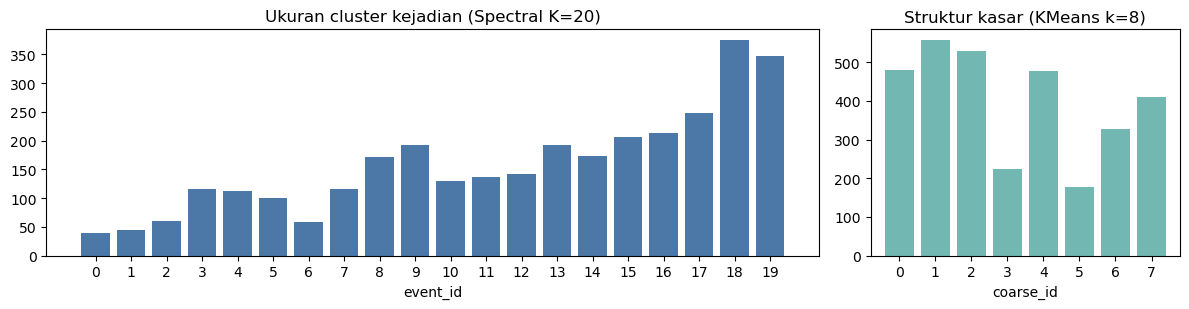

In [5]:
sc = SpectralClustering(n_clusters=K, affinity="nearest_neighbors", n_neighbors=KNN,
                        assign_labels="cluster_qr", random_state=SEED)
event_id = sc.fit_predict(Z)

km = KMeans(K_KASAR, n_init=10, random_state=SEED)
coarse_id = km.fit_predict(Z)

ukuran = pd.Series(event_id).value_counts().sort_index()
ukuran_kasar = pd.Series(coarse_id).value_counts().sort_index()
print("Ukuran cluster kejadian:", ukuran.to_dict())
print("Ukuran struktur kasar  :", ukuran_kasar.to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [K, K_KASAR]})
ax[0].bar(ukuran.index, ukuran.values, color="#4C78A8")
ax[0].set_title(f"Ukuran cluster kejadian (Spectral K={K})"); ax[0].set_xlabel("event_id"); ax[0].set_xticks(ukuran.index)
ax[1].bar(ukuran_kasar.index, ukuran_kasar.values, color="#72B7B2")
ax[1].set_title(f"Struktur kasar (KMeans k={K_KASAR})"); ax[1].set_xlabel("coarse_id"); ax[1].set_xticks(ukuran_kasar.index)
plt.tight_layout(); plt.show()

## 4. Gate kualitas
Jika ada cek yang GAGAL, notebook berhenti di sini (ubah K / PCA, jangan lanjut).

η² = Σ n_c (mean_c − mean)² / Σ (x − mean)²  — porsi variasi yang dijelaskan pembagian cluster.

In [6]:
def eta2(label, x):
    # eta kuadrat; baris NaN dilewati
    x = np.asarray(x, dtype=float); ok = ~np.isnan(x)
    lab, x = np.asarray(label)[ok], x[ok]
    m = x.mean(); total = ((x - m) ** 2).sum()
    antar = sum((lab == c).sum() * (x[lab == c].mean() - m) ** 2 for c in np.unique(lab))
    return antar / total if total > 0 else 0.0

# 1) Ketahanan noise: noise normal (std = NOISE_SKALA x std(Z)), seed tetap -> bulatkan -> cluster ulang
rng = np.random.default_rng(SEED)
Z_noise = np.round(Z + rng.normal(0, NOISE_SKALA * Z.std(), Z.shape), ROUND)
lab_noise = SpectralClustering(n_clusters=K, affinity="nearest_neighbors", n_neighbors=KNN,
                               assign_labels="cluster_qr", random_state=SEED).fit_predict(Z_noise)
ari_noise = adjusted_rand_score(event_id, lab_noise)

# 2) Ketahanan parameter: n_neighbors = KNN_UJI
lab_knn = SpectralClustering(n_clusters=K, affinity="nearest_neighbors", n_neighbors=KNN_UJI,
                             assign_labels="cluster_qr", random_state=SEED).fit_predict(Z)
ari_knn = adjusted_rand_score(event_id, lab_knn)

# 3) Bias artefak
artefak = {
    "is_gray (pre+post)":        art["is_gray_pre"].astype(float) + art["is_gray_post"].astype(float),
    "black_frac (pre+post)":     art["black_frac_pre"] + art["black_frac_post"],
    "scanline_score (pre+post)": art["scanline_score_pre"] + art["scanline_score_post"],
    "color_shift":               phys["color_shift"],
    "|brightness post-pre|":     (art["brightness_post"] - art["brightness_pre"]).abs(),
}
bias = pd.Series({k: eta2(event_id, v) for k, v in artefak.items()}, name="eta2").round(4)
print("η² event_id vs artefak:"); print(bias.to_string(), "\n")

# 4) Ukuran cluster terkecil
min_size = int(ukuran.min())

gate = pd.DataFrame({
    "nilai":  [ari_noise, ari_knn, bias.max(), min_size],
    "target": [f">= {GATE_ARI_NOISE}", f">= {GATE_ARI_KNN}", f"<= {GATE_BIAS_MAX}", f">= {GATE_MIN_SIZE}"],
    "lulus":  [ari_noise >= GATE_ARI_NOISE, ari_knn >= GATE_ARI_KNN,
               bias.max() <= GATE_BIAS_MAX, min_size >= GATE_MIN_SIZE],
}, index=["ARI noise", f"ARI kNN={KNN_UJI}", f"bias maks ({bias.idxmax()})", "ukuran min"])
gate["status"] = np.where(gate["lulus"], "LULUS", "GAGAL")
GATE = {"ari_noise": round(float(ari_noise), 4), "ari_knn25": round(float(ari_knn), 4),
        "bias_max": round(float(bias.max()), 4), "bias_max_kolom": bias.idxmax(), "min_size": min_size,
        "bias_per_artefak": bias.to_dict(), "lulus": bool(gate["lulus"].all())}
display(gate.drop(columns="lulus").round(4))

if not GATE["lulus"]:
    raise RuntimeError("GATE GAGAL -> berhenti. Laporkan ke Fahmi; coba K 15/25 atau PCA 32.")
print("Semua gate LULUS")

η² event_id vs artefak:
is_gray (pre+post)           0.0327
black_frac (pre+post)        0.0240
scanline_score (pre+post)    0.1108
color_shift                  0.0301
|brightness post-pre|        0.0131 



,nilai,target,status
ARI noise,0.9922,>= 0.95,LULUS
ARI kNN=25,0.8636,>= 0.8,LULUS
bias maks (scanline_score (pre+post)),0.1108,<= 0.15,LULUS
ukuran min,40.0000,>= 30,LULUS


Semua gate LULUS


In [7]:
# Perbandingan dengan v1 (hanya dibaca, v1 tidak diubah)
ev_v1 = pd.read_parquet(f"{V1_DIR}/events.parquet")
assert (ev_v1["Id"].to_numpy() == ids).all()
ARI_V1 = {"event_id": round(float(adjusted_rand_score(ev_v1["event_id"], event_id)), 4),
          "coarse_id": round(float(adjusted_rand_score(ev_v1["coarse_id"], coarse_id)), 4)}
print("ARI v2 vs v1:", ARI_V1)

ARI v2 vs v1: {'event_id': 0.9949, 'coarse_id': 0.9969}


## 5. Sumbu indikator (v2)
Enam sumbu, satu kolom per sumbu. `air_pre` adalah indikator warna (NaN jika warna tidak bisa dipercaya).
Indikator lain (`d_exg_v4`, `d_water`, `top10_share`, `radial_decay`, `frac_chg_*`, `delta_edge`, `edge_ratio`) tidak dipakai.

In [8]:
# sumbu -> (kolom, tabel sumber)
SUMBU = {
    "kota":    ("edge_pre",        art),
    "sebaran": ("spatial_entropy", patch),
    "tekstur": ("d_entropy",       phys),
    "gelap":   ("d_dark",          phys),
    "arah":    ("com_shift",       patch),
    "air_pre": ("water_rel_pre",   phys),
}
SUMBU_WARNA = ["air_pre"]
SUMBU_NAMA = list(SUMBU)
KELAS = ["Earthquake", "Explosion", "Fire", "Hurricane", "Tsunami", "Volcano"]

nilai = pd.DataFrame({s: df[kol].to_numpy(dtype=float) for s, (kol, df) in SUMBU.items()})
ringkas = pd.DataFrame({
    "kolom": [SUMBU[s][0] for s in SUMBU_NAMA],
    "n_nan": nilai.isna().sum().to_numpy(),
    "min": nilai.min().to_numpy(), "median": nilai.median().to_numpy(), "max": nilai.max().to_numpy(),
    "eta2_cluster": [eta2(event_id, nilai[s]) for s in SUMBU_NAMA],
}, index=SUMBU_NAMA).round(4)
display(ringkas)
print("Korelasi Spearman antar sumbu (per foto):")
nilai.corr(method="spearman").round(2)

,kolom,n_nan,min,median,max,eta2_cluster
kota,edge_pre,0,0.0336,0.2470,0.9172,0.5008
sebaran,spatial_entropy,0,0.8720,0.9288,0.9664,0.2367
tekstur,d_entropy,0,-2.0704,-0.0413,1.9442,0.0439
gelap,d_dark,0,-0.3519,-0.0015,0.4630,0.0387
arah,com_shift,0,0.0015,0.0784,0.5309,0.0342
air_pre,water_rel_pre,2054,0.0000,0.0022,0.1976,0.0783


Korelasi Spearman antar sumbu (per foto):


,kota,sebaran,tekstur,gelap,arah,air_pre
kota,1.00,-0.21,-0.16,-0.16,-0.03,0.24
sebaran,-0.21,1.00,-0.01,-0.01,-0.15,-0.07
tekstur,-0.16,-0.01,1.00,0.07,-0.03,0.06
gelap,-0.16,-0.01,0.07,1.00,0.05,-0.09
arah,-0.03,-0.15,-0.03,0.05,1.00,-0.04
air_pre,0.24,-0.07,0.06,-0.09,-0.04,1.00


## 6. Profil cluster (robust)
Median setiap sumbu per cluster (`air_pre` hanya jika ≥ `MIN_WARNA` nilai valid).
Z robust antar cluster: z = (median_cluster − median dari semua median) / (1,4826 × MAD), MAD = median |median_cluster − median dari semua median|. NaN diabaikan.

In [9]:
def profil_median(lab, nil):
    # median per cluster; sumbu warna hanya jika nilai valid >= MIN_WARNA
    df = nil.copy(); df["lab"] = np.asarray(lab)
    g = df.groupby("lab")
    med  = g[SUMBU_NAMA].median().reindex(range(K)).rename_axis("event_id")
    nval = g[SUMBU_NAMA].count().reindex(range(K)).fillna(0).astype(int).rename_axis("event_id")
    for s in SUMBU_WARNA:
        med.loc[nval[s] < MIN_WARNA, s] = np.nan
    return med, nval

def z_robust(med):
    pusat = med.median()                          # median dari semua median (NaN dilewati)
    mad = (med - pusat).abs().median()
    return (med - pusat) / (1.4826 * mad)

med, nval = profil_median(event_id, nilai)
zr = z_robust(med)

profil = pd.DataFrame({"n": ukuran})
for s in SUMBU_NAMA: profil["med_" + s] = med[s]
for s in SUMBU_NAMA: profil["z_" + s] = zr[s]
for s in SUMBU_NAMA: profil["nvalid_" + s] = nval[s]
profil.index.name = "event_id"

print(f"Cluster dengan air_pre terpakai: {int(med['air_pre'].notna().sum())} dari {K}")
print("Foto warna valid per cluster:", nval["air_pre"].to_dict())
zr.round(2)

Cluster dengan air_pre terpakai: 18 dari 20
Foto warna valid per cluster: {0: 9, 1: 12, 2: 23, 3: 29, 4: 44, 5: 16, 6: 19, 7: 36, 8: 74, 9: 63, 10: 56, 11: 38, 12: 49, 13: 65, 14: 45, 15: 76, 16: 68, 17: 93, 18: 149, 19: 162}


,kota,sebaran,tekstur,gelap,arah,air_pre
event_id,,,,,,
0,5.21,-0.60,0.10,-5.65,-2.80,NaN
1,-1.90,1.90,2.25,0.35,-0.48,NaN
2,-0.97,0.06,0.81,0.77,3.18,-0.74
3,-0.55,2.60,-2.48,0.33,-1.90,-0.89
4,-0.55,1.05,-0.78,0.96,0.19,0.65
5,1.82,2.66,1.50,10.07,-1.35,-0.04
6,-0.33,2.38,-0.71,0.32,-1.54,-0.61
7,-0.80,0.23,-0.10,-0.63,0.51,0.04
8,-0.20,0.30,-0.77,-1.36,0.24,-0.85


## 7. Bobot sumbu = reliabilitas split-half
Untuk setiap sumbu, `N_SPLIT_REL` kali (seed 0, 1, 2, …): foto dibagi acak dua bagian (`rng.random(N) < 0.5`),
median per cluster di tiap bagian (median biasa; cluster NaN diabaikan), lalu korelasi Pearson kedua vektor median.
Bobot = max(0, rata-rata korelasi).

In [10]:
rel = {s: [] for s in SUMBU_NAMA}
for seed in range(N_SPLIT_REL):
    bag = np.random.default_rng(seed).random(N) < 0.5
    for s in SUMBU_NAMA:
        m1 = pd.Series(nilai[s].to_numpy()[bag]).groupby(event_id[bag]).median().reindex(range(K))
        m2 = pd.Series(nilai[s].to_numpy()[~bag]).groupby(event_id[~bag]).median().reindex(range(K))
        ok = m1.notna() & m2.notna()
        rel[s].append(np.corrcoef(m1[ok], m2[ok])[0, 1])

bobot_tab = pd.DataFrame({
    "kolom": [SUMBU[s][0] for s in SUMBU_NAMA],
    "reliabilitas": [np.mean(rel[s]) for s in SUMBU_NAMA],
    "std": [np.std(rel[s]) for s in SUMBU_NAMA],
}, index=SUMBU_NAMA)
bobot_tab["bobot"] = bobot_tab["reliabilitas"].clip(lower=0)
bobot_tab.index.name = "sumbu"
BOBOT = bobot_tab["bobot"].to_dict()
bobot_tab.round(4)

,kolom,reliabilitas,std,bobot
sumbu,,,,
kota,edge_pre,0.9867,0.0065,0.9867
sebaran,spatial_entropy,0.9339,0.0230,0.9339
tekstur,d_entropy,0.2457,0.2324,0.2457
gelap,d_dark,0.5719,0.2483,0.5719
arah,com_shift,0.7138,0.0851,0.7138
air_pre,water_rel_pre,0.5733,0.0957,0.5733


## 8. `rules.json` v2 (desain D2b, dikunci Fahmi)
Ditulis persis ke folder output, lalu dimuat kembali. Notebook menolak lanjut jika `status` bukan `"dikunci"`.
Aturan diturunkan dari deskripsi resmi kelas panitia dengan bantuan AI (Claude); dijalankan seluruhnya oleh kode.

In [11]:
RULES_TEKS = '''{
  "versi": "v2",
  "status": "dikunci",
  "dikunci_oleh": "Fahmi",
  "dikunci_pada": "2026-11-27 22:36",
  "desain": "D2b",
  "sumber": "Diturunkan dari deskripsi resmi kelas panitia dengan bantuan AI (Claude); dijalankan seluruhnya oleh kode",
  "kelas": {
    "Fire":       {"gelap": 1, "kota": -1},
    "Volcano":    {"tekstur": -1, "sebaran": 1},
    "Tsunami":    {"air_pre": 1, "arah": 1},
    "Hurricane":  {"sebaran": 1, "kota": -1, "gelap": -1},
    "Earthquake": {"kota": 1, "sebaran": 1},
    "Explosion":  {"kota": 1, "sebaran": -1}
  },
  "alasan": {
    "Fire": "Area terbakar gelap; terjadi di vegetasi/lahan, umumnya bukan kota padat",
    "Volcano": "Material vulkanik menutupi permukiman dan lahan: permukaan tertutup rata, area luas",
    "Tsunami": "Gelombang laut menggenangi daratan dan mengubah garis pantai: lokasi pesisir, perubahan dari satu sisi",
    "Hurricane": "Merontokkan vegetasi dan merusak struktur secara tersebar: tersebar, area bervegetasi, tidak menggelap",
    "Earthquake": "Kerusakan membentang luas pada struktur",
    "Explosion": "Merusak area di sekitar titik kejadian secara radial: kerusakan terpusat"
  },
  "skor": "skor_kelas = jumlah(tanda × z_sumbu × bobot_sumbu) / jumlah(bobot_sumbu), sumbu NaN dilewati; lalu setiap kolom skor kelas di-z-score (biasa) antar cluster; kelas = argmax",
  "keyakinan": "bootstrap N_BOOT; cluster lemah jika keyakinan < YAKIN_MIN"
}
'''

# Pilih folder versi yang belum ada (tidak menimpa)
induk, nama_v = os.path.split(OUTPUT_DIR)
nomor = int(nama_v.lstrip("v"))
OUT = OUTPUT_DIR
while os.path.exists(OUT):
    nomor += 1
    OUT = os.path.join(induk, f"v{nomor}")
os.makedirs(OUT)
RULES_PATH = os.path.join(OUT, "rules.json")
with open(RULES_PATH, "w", encoding="utf-8") as f:
    f.write(RULES_TEKS)

with open(RULES_PATH, encoding="utf-8") as f:
    RULES = json.load(f)
assert RULES["status"] == "dikunci", "rules.json belum dikunci -> berhenti"
assert sorted(RULES["kelas"]) == KELAS, "nama kelas salah"
for k, a in RULES["kelas"].items():
    for s, t in a.items():
        assert s in SUMBU_NAMA and t in (1, -1), f"{k}: {s}={t} tidak valid"
print("Folder output:", OUT, "| status aturan:", RULES["status"], "| desain:", RULES["desain"])
pd.DataFrame(RULES["kelas"]).T.reindex(columns=SUMBU_NAMA).fillna(0).astype(int)

Folder output: v2 | status aturan: dikunci | desain: D2b


,kota,sebaran,tekstur,gelap,arah,air_pre
Fire,-1,0,0,1,0,0
Volcano,0,1,-1,0,0,0
Tsunami,0,0,0,0,1,1
Hurricane,-1,1,0,-1,0,0
Earthquake,1,1,0,0,0,0
Explosion,1,-1,0,0,0,0


## 9. Skor dan penamaan
1. Skor kelas = jumlah(tanda × z × bobot) / jumlah(bobot) atas sumbu yang tidak NaN.
2. Setiap kolom skor kelas di-z-score (rata-rata/std populasi) antar cluster → skor terstandarisasi.
3. Kelas awal = argmax. Kelas kosong → pengganti optimal dengan `linear_sum_assignment`
   (baris = kelas kosong, kolom = cluster yang bukan satu-satunya di kelasnya, biaya = pengorbanan). Diulang sampai semua kelas terisi.
4. Margin = skor tertinggi − kedua (informasi).

In [12]:
def skor_kelas(z, bobot):
    # skor mentah per kelas lalu distandarisasi antar cluster
    S = pd.DataFrame(index=z.index, columns=KELAS, dtype=float)
    for k in KELAS:
        atas = pd.Series(0.0, index=z.index); bawah = pd.Series(0.0, index=z.index)
        for s, t in RULES["kelas"][k].items():
            ada = z[s].notna()
            atas += (t * z[s] * bobot[s]).where(ada, 0.0)
            bawah += pd.Series(float(bobot[s]), index=z.index).where(ada, 0.0)
        S[k] = atas / bawah.replace(0, np.nan)
    return (S - S.mean()) / S.std(ddof=0)

def isi_kelas_kosong(S, nama):
    # pengganti optimal untuk kelas tanpa cluster; diulang sampai terisi atau tidak mungkin
    nama = nama.copy(); log = []
    for _ in range(10):
        kosong = [k for k in KELAS if (nama == k).sum() == 0]
        boleh = [e for e in nama.index if (nama == nama[e]).sum() > 1]
        if not kosong or not boleh:
            break
        biaya = np.array([[S.loc[e, nama[e]] - S.loc[e, k] for e in boleh] for k in kosong])
        biaya = np.nan_to_num(biaya, nan=1e6)
        baris, kolom = linear_sum_assignment(biaya)
        for i, j in zip(baris, kolom):
            e = boleh[j]
            log.append({"event_id": int(e), "dari": nama[e], "ke": kosong[i], "pengorbanan": round(float(biaya[i, j]), 4)})
            nama[e] = kosong[i]
    return nama, log

S = skor_kelas(zr, BOBOT)
kelas_awal = S.idxmax(axis=1)
nama_final, log_pindah = isi_kelas_kosong(S, kelas_awal)
urut = np.sort(S.to_numpy(), axis=1)
margin = pd.Series(urut[:, -1] - urut[:, -2], index=S.index)

print("Kelas awal per cluster:", kelas_awal.value_counts().reindex(KELAS).fillna(0).astype(int).to_dict())
print("Pemindahan kelas kosong:", log_pindah if log_pindah else "tidak ada")
print("Kelas tetap kosong:", [k for k in KELAS if (nama_final == k).sum() == 0] or "tidak ada")
S.round(3)

Kelas awal per cluster: {'Earthquake': 2, 'Explosion': 4, 'Fire': 0, 'Hurricane': 4, 'Tsunami': 6, 'Volcano': 4}
Pemindahan kelas kosong: [{'event_id': 4, 'dari': 'Volcano', 'ke': 'Fire', 'pengorbanan': 0.1082}]
Kelas tetap kosong: tidak ada


,Earthquake,Explosion,Fire,Hurricane,Tsunami,Volcano
event_id,,,,,,
0,2.448,2.398,-3.216,-0.911,-2.857,-0.771
1,-0.608,-1.636,0.977,1.543,-0.411,0.728
2,-1.133,-0.496,0.703,0.348,1.603,-0.407
3,0.688,-1.347,0.439,1.271,-1.436,2.238
4,-0.253,-0.718,0.580,0.516,0.509,0.688
5,2.250,-0.356,1.732,-1.992,-0.713,1.466
6,0.700,-1.160,0.345,1.094,-1.094,1.705
7,-0.918,-0.499,0.318,0.682,0.409,-0.083
8,-0.489,-0.269,-0.089,0.635,-0.170,0.104


## 10. Keyakinan bootstrap
Untuk b = 0 … `N_BOOT`−1 (seed = b): di setiap cluster ambil sampel foto dengan pengembalian sebanyak ukuran cluster →
median → z robust → skor → standarisasi → argmax (bobot sumbu tetap; tanpa langkah kelas kosong).
Keyakinan = porsi bootstrap dengan argmax = kelas final. `is_weak` = keyakinan < `YAKIN_MIN`.

In [13]:
idx_cluster = [np.where(event_id == e)[0] for e in range(K)]
cocok = np.zeros(K)
for b in range(N_BOOT):
    rng_b = np.random.default_rng(b)
    idx = np.concatenate([rng_b.choice(ix, size=len(ix), replace=True) for ix in idx_cluster])
    med_b, _ = profil_median(event_id[idx], nilai.iloc[idx].reset_index(drop=True))
    S_b = skor_kelas(z_robust(med_b), BOBOT)
    cocok += (S_b.idxmax(axis=1).to_numpy() == nama_final.to_numpy())
keyakinan = pd.Series(cocok / N_BOOT, index=range(K))

names = pd.DataFrame({
    "Phenomenon": nama_final, "n": ukuran, "keyakinan": keyakinan.round(4),
    "is_weak": keyakinan < YAKIN_MIN, "margin": margin.round(4),
})
names.index.name = "event_id"
for k in KELAS:
    names["skor_" + k] = S[k].round(4)
pindah = {d["event_id"]: d for d in log_pindah}
names["dipindah_kelas_kosong"] = [pindah[e]["dari"] if e in pindah else "" for e in names.index]
names["pengorbanan"] = [pindah[e]["pengorbanan"] if e in pindah else np.nan for e in names.index]

print("Cluster lemah (keyakinan <", YAKIN_MIN, "):", int(names["is_weak"].sum()), "dari", K)
names[["Phenomenon", "n", "keyakinan", "is_weak", "margin", "dipindah_kelas_kosong", "pengorbanan"]]

Cluster lemah (keyakinan < 0.6 ): 4 dari 20


,Phenomenon,n,keyakinan,is_weak,margin,dipindah_kelas_kosong,pengorbanan
event_id,,,,,,,
0,Earthquake,40,0.595,True,0.0502,,NaN
1,Hurricane,45,0.805,False,0.5663,,NaN
2,Tsunami,61,0.855,False,0.8993,,NaN
3,Volcano,116,1.000,False,0.9678,,NaN
4,Fire,112,0.430,True,0.1082,Volcano,0.1082
5,Earthquake,101,0.680,False,0.5181,,NaN
6,Volcano,58,0.980,False,0.6102,,NaN
7,Hurricane,116,0.665,False,0.2735,,NaN
8,Hurricane,172,0.975,False,0.5309,,NaN


In [14]:
# Distribusi kelas
distribusi = pd.DataFrame({
    "n_cluster": names["Phenomenon"].value_counts(),
    "n_foto": names.groupby("Phenomenon")["n"].sum(),
    "n_cluster_lemah": names[names["is_weak"]]["Phenomenon"].value_counts(),
    "keyakinan_rata2": names.groupby("Phenomenon")["keyakinan"].mean().round(3),
}).reindex(KELAS)
distribusi[["n_cluster", "n_foto", "n_cluster_lemah"]] = distribusi[["n_cluster", "n_foto", "n_cluster_lemah"]].fillna(0).astype(int)
distribusi["porsi_foto"] = (distribusi["n_foto"] / N).round(3)
distribusi

,n_cluster,n_foto,n_cluster_lemah,keyakinan_rata2,porsi_foto
Phenomenon,,,,,
Earthquake,2,141,1,0.638,0.044
Explosion,4,672,1,0.810,0.211
Fire,1,112,1,0.430,0.035
Hurricane,4,681,0,0.805,0.214
Tsunami,6,1226,1,0.664,0.386
Volcano,3,348,0,0.918,0.109


## 11. Uji ketahanan per sumbu
Setiap sumbu bergiliran diberi bobot 0 → penamaan ulang (termasuk langkah kelas kosong, tanpa bootstrap) →
jumlah cluster yang namanya berubah. **Hanya laporan**, bukan dasar mengubah aturan.

In [15]:
tahan = []
for s in SUMBU_NAMA:
    b0 = dict(BOBOT); b0[s] = 0.0
    S0 = skor_kelas(zr, b0)
    nama0, _ = isi_kelas_kosong(S0, S0.idxmax(axis=1))
    beda = nama0 != nama_final
    tahan.append({"sumbu": s, "bobot_asli": round(BOBOT[s], 4), "n_cluster_berubah": int(beda.sum()),
                  "cluster_berubah": " ".join(f"{e}:{nama_final[e]}->{nama0[e]}" for e in nama0.index[beda])})
ketahanan = pd.DataFrame(tahan).set_index("sumbu")
ketahanan

,bobot_asli,n_cluster_berubah,cluster_berubah
sumbu,,,
kota,0.9867,10,0:Earthquake->Hurricane 1:Hurricane->Earthquak...
sebaran,0.9339,8,0:Earthquake->Explosion 4:Fire->Volcano 5:Eart...
tekstur,0.2457,1,14:Volcano->Hurricane
gelap,0.5719,4,4:Fire->Hurricane 7:Hurricane->Fire 8:Hurrican...
arah,0.7138,6,2:Tsunami->Fire 4:Fire->Volcano 9:Explosion->T...
air_pre,0.5733,4,4:Fire->Volcano 12:Tsunami->Explosion 15:Tsuna...


## 12. `is_core` dan `weight`
- Kedekatan 0–1 di dalam cluster dari peringkat jarak ke pusat (ruang `Z`); 1 = paling dekat.
- `is_core`: `CORE_FRAC_KUAT` foto terdekat (cluster kuat) atau `CORE_FRAC_LEMAH` (cluster lemah).
- Jika `is_core` suatu kelas < `MIN_CORE_KELAS`: porsi cluster kelas itu dinaikkan +0,1 (maks 0,5) sampai terpenuhi atau mentok.
- `weight` = keyakinan cluster × kedekatan. **Wajib**: keenam kelas punya foto `is_core`.

In [16]:
# Peringkat kedekatan di dalam cluster (0 = paling dekat)
peringkat = np.zeros(N, dtype=int)
kedekatan = np.zeros(N)
for e, ix in enumerate(idx_cluster):
    jarak = np.linalg.norm(Z[ix] - Z[ix].mean(axis=0), axis=1)
    r = np.empty(len(ix), dtype=int); r[np.argsort(jarak, kind="stable")] = np.arange(len(ix))
    peringkat[ix] = r
    kedekatan[ix] = 1 - r / (len(ix) - 1)

porsi = pd.Series(np.where(names["is_weak"], CORE_FRAC_LEMAH, CORE_FRAC_KUAT), index=names.index)
nama_foto = names["Phenomenon"].reindex(event_id).to_numpy()

def hitung_core(porsi):
    batas = np.round(porsi.reindex(event_id).to_numpy() * ukuran.reindex(event_id).to_numpy())
    return peringkat < batas

is_core = hitung_core(porsi)
log_core = []
for k in KELAS:
    cl = names.index[names["Phenomenon"] == k]
    while is_core[nama_foto == k].sum() < MIN_CORE_KELAS and (porsi[cl] < CORE_FRAC_KUAT - 1e-9).any():
        porsi[cl] = np.minimum(np.round(porsi[cl] + 0.1, 1), CORE_FRAC_KUAT)
        is_core = hitung_core(porsi)
        log_core.append({"kelas": k, "porsi_baru": {int(e): float(porsi[e]) for e in cl}, "n_core": int(is_core[nama_foto == k].sum())})

weight = keyakinan.reindex(event_id).to_numpy() * kedekatan
names["porsi_core"] = porsi

core_kelas = pd.DataFrame({
    "n_is_core": pd.Series(is_core).groupby(nama_foto).sum(),
    "n_foto": pd.Series(nama_foto).value_counts(),
    "weight_rata2_core": pd.Series(weight[is_core]).groupby(nama_foto[is_core]).mean().round(3),
}).reindex(KELAS).fillna(0)
core_kelas["n_is_core"] = core_kelas["n_is_core"].astype(int)
core_kelas["memenuhi_min"] = core_kelas["n_is_core"] >= MIN_CORE_KELAS
print("Penyesuaian porsi:", log_core if log_core else "tidak ada")
print("Total is_core:", int(is_core.sum()), "dari", N)
display(core_kelas)

tanpa_core = [k for k in KELAS if core_kelas.loc[k, "n_is_core"] == 0]
if tanpa_core:
    raise RuntimeError(f"Kelas tanpa foto is_core: {tanpa_core} -> berhenti, laporkan ke Fahmi.")
print("Keenam kelas punya foto is_core")

Penyesuaian porsi: [{'kelas': 'Fire', 'porsi_baru': {4: 0.3}, 'n_core': 34}]
Total is_core: 1434 dari 3180


,n_is_core,n_foto,weight_rata2_core,memenuhi_min
Earthquake,58,141,0.517,True
Explosion,278,672,0.659,True
Fire,34,112,0.366,True
Hurricane,340,681,0.608,True
Tsunami,550,1226,0.489,True
Volcano,174,348,0.665,True


Keenam kelas punya foto is_core


## 13. Simpan output
Ke folder `OUT` yang dipilih di bagian 8 (`v2`, atau nomor berikutnya jika sudah ada). `v1/` tidak disentuh.

In [17]:
# events.parquet
events = pd.DataFrame({"Id": ids, "event_id": event_id.astype(int), "coarse_id": coarse_id.astype(int),
                       "is_core": is_core, "weight": np.round(weight, 6)})
events.to_parquet(f"{OUT}/events.parquet", index=False)

# event_names.csv
kolom = (["Phenomenon", "n", "keyakinan", "is_weak", "margin"] + ["skor_" + k for k in KELAS]
         + ["dipindah_kelas_kosong", "pengorbanan"])
names[kolom].reset_index().to_csv(f"{OUT}/event_names.csv", index=False)

# cluster_profile.csv, bobot_sumbu.csv, ketahanan_sumbu.csv
profil.reset_index().to_csv(f"{OUT}/cluster_profile.csv", index=False)
bobot_tab.reset_index().to_csv(f"{OUT}/bobot_sumbu.csv", index=False)
ketahanan.reset_index().to_csv(f"{OUT}/ketahanan_sumbu.csv", index=False)

# meta.json
meta = {
    "versi": os.path.basename(OUT),
    "oleh": "Fahmi",
    "tanggal": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "input": {"fitur": FITUR_DIR.replace("../", ""), "phys": PHYS_PATH.replace("../", ""),
              "embedding": "dino_color_pre + dino_color_post (DINOv2-L FP32, cabang warna)",
              "meta_A": {k: META_A["pengaturan"].get(k) for k in ["backbone", "img_size", "tta", "precision", "ambang_color_shift"]}},
    "pengaturan": {"metode": "spectral", "K": K, "pca": PCA_DIM, "knn": KNN, "seed": SEED, "round": ROUND,
                   "assign_labels": "cluster_qr", "k_kasar": K_KASAR, "noise_skala": NOISE_SKALA,
                   "min_warna": MIN_WARNA, "n_split_rel": N_SPLIT_REL, "n_boot": N_BOOT, "yakin_min": YAKIN_MIN,
                   "core_frac_kuat": CORE_FRAC_KUAT, "core_frac_lemah": CORE_FRAC_LEMAH,
                   "min_core_kelas": MIN_CORE_KELAS, "pca_variansi": round(float(evr.sum()), 4)},
    "gate": GATE,
    "ari_vs_v1": ARI_V1,
    "rules": {"desain": RULES["desain"], "status": RULES["status"], "dikunci_pada": RULES["dikunci_pada"]},
    "sumbu": {s: SUMBU[s][0] for s in SUMBU_NAMA},
    "bobot_sumbu": {s: round(float(BOBOT[s]), 4) for s in SUMBU_NAMA},
    "distribusi_kelas": {k: {"n_cluster": int(distribusi.loc[k, "n_cluster"]), "n_foto": int(distribusi.loc[k, "n_foto"])}
                         for k in KELAS},
    "n_cluster_lemah": int(names["is_weak"].sum()),
    "pemindahan_kelas_kosong": log_pindah,
    "is_core_per_kelas": {k: int(core_kelas.loc[k, "n_is_core"]) for k in KELAS},
    "penyesuaian_porsi_core": log_core,
    "ketahanan_sumbu": {s: int(ketahanan.loc[s, "n_cluster_berubah"]) for s in SUMBU_NAMA},
    "alasan_pembaruan_v2": [
        "v1: is_core hanya mencakup 2 kelas (Explosion, Tsunami), sehingga classifier tidak bisa dilatih 6 kelas",
        "v1: Hurricane dan Volcano punya rumus keluarga 2 identik sehingga tidak bisa dibedakan",
        "v1: di cluster tanpa data warna, seluruh keluarga 1 dibuang termasuk indikator struktur",
        "v1: indikator patch hampir satu sumbu; aturan Explosion memakai dua indikator berlawanan (top10_share vs radial_decay, r = -0,82)",
        "v1: kelas dengan sedikit indikator lebih sering menang; ambang margin tetap 0,5 tidak sesuai skala skor",
        "v1: d_exg_v4 tidak punya sinyal di level cluster (reliabilitas split-half ~ 0)",
    ],
    "keterangan_ai": "Aturan rules.json v2 (D2b) diturunkan dari deskripsi resmi kelas panitia dengan bantuan AI (Claude), "
                     "dikunci oleh Fahmi, dan dijalankan seluruhnya oleh kode. Bobot, z-score, dan keyakinan dihitung otomatis dari data tanpa label.",
    "versi_lib": VERSI_LIB,
    "catatan": "Penamaan dari rules.json v2 (dikunci Fahmi), tanpa label manual. Input hafizh/v3.1 (DINOv2-L FP32).",
}
with open(f"{OUT}/meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

# Cek akhir
cek_ev = pd.read_parquet(f"{OUT}/events.parquet")
cek_nm = pd.read_csv(f"{OUT}/event_names.csv")
assert len(cek_ev) == N and cek_ev["Id"].is_unique and (cek_ev["Id"].to_numpy() == ids).all()
assert set(cek_nm["Phenomenon"]) == set(KELAS) and len(cek_nm) == K
assert len(os.listdir(OUT)) == 7
print("Disimpan ke", OUT, ":", sorted(os.listdir(OUT)))
print("Cek akhir LULUS")

Disimpan ke v2 : ['bobot_sumbu.csv', 'cluster_profile.csv', 'event_names.csv', 'events.parquet', 'ketahanan_sumbu.csv', 'meta.json', 'rules.json']
Cek akhir LULUS
